# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [4]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv(r'C:\Users\Amulya MJ\data-viz-class-material-w2026\data\global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


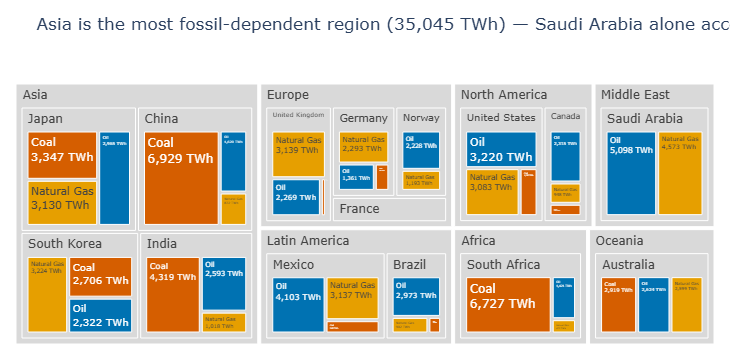

In [5]:
# Task 1

df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()


fossil_colors = {'Coal': '#D55E00', 'Oil': '#0072B2', 'Natural Gas': '#E69F00'}
PARENT_GREY = '#D9D9D9'

region_tot  = df_fossil.groupby('Region')['TWh'].sum().sort_values(ascending=False)
country_tot = df_fossil.groupby('Country')['TWh'].sum().sort_values(ascending=False)
top_region, top_region_twh   = region_tot.index[0], region_tot.iloc[0]
top_country, top_country_twh = country_tot.index[0], country_tot.iloc[0]

fig1 = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    title=(f"{top_region} is the most fossil-dependent region ({top_region_twh:,.0f} TWh) — "
           f"{top_country} alone accounts for {top_country_twh:,.0f} TWh")
)

tm = fig1.data[0]
node_colors = [
    fossil_colors.get(label, PARENT_GREY) if node_id.count('/') == 2 else PARENT_GREY
    for node_id, label in zip(tm.ids, tm.labels)
]
fig1.update_traces(
    marker_colors=node_colors,
    texttemplate='%{label}<br>%{value:,.0f} TWh',      # TWh only, no percentages
    hovertemplate='%{id}<br>%{value:,.0f} TWh<extra></extra>',
    root_color='white'
)
fig1.update_layout(margin=dict(t=60, l=10, r=10, b=10))
fig1.show()

## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

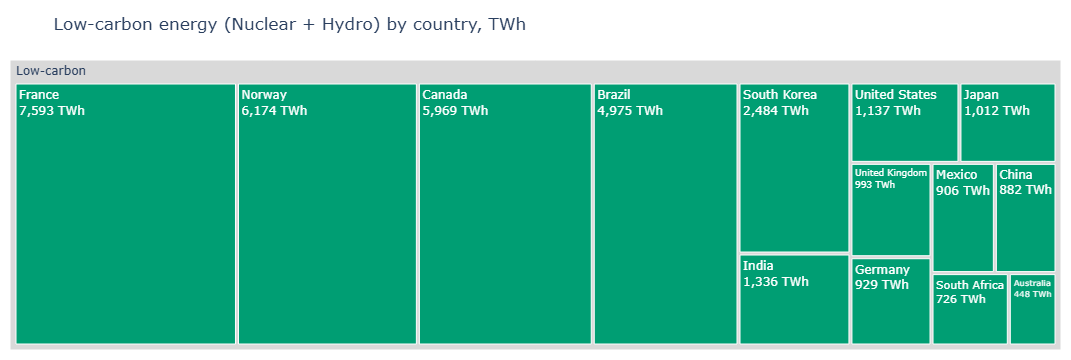

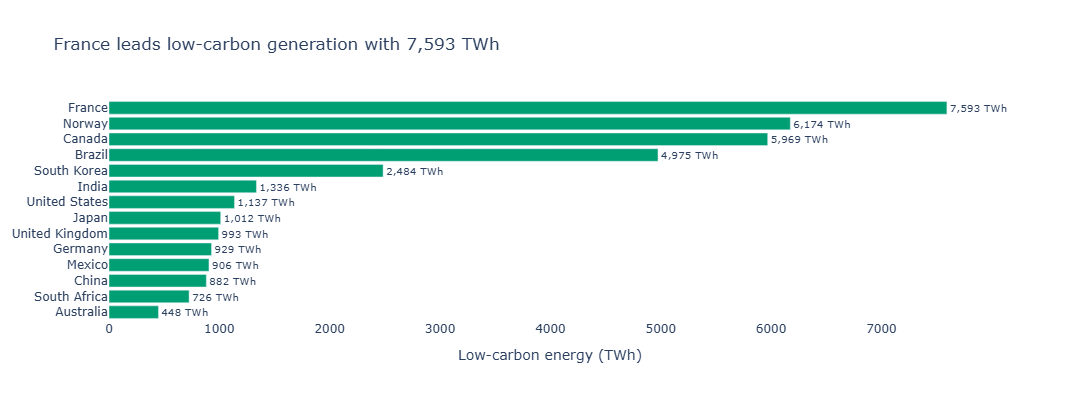

In [9]:
# Task 2:

df_low = (
    df.loc[df['Source_Type'] == 'Low-carbon']
      .groupby('Country', as_index=False)['TWh'].sum()
      .sort_values('TWh', ascending=False)
)
df_low['All'] = 'Low-carbon'            # dummy root node

LOW_CARBON_COLOR = '#009E73'            # Okabe-Ito bluish green
leader, leader_twh = df_low.iloc[0]['Country'], df_low.iloc[0]['TWh']

fig2a = px.treemap(
    df_low,
    path=['All', 'Country'],
    values='TWh',
    title='Low-carbon energy (Nuclear + Hydro) by country, TWh'
)
tm2 = fig2a.data[0]
fig2a.update_traces(
    marker_colors=[PARENT_GREY if pid == '' else LOW_CARBON_COLOR for pid in tm2.parents],
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='%{label}<br>%{value:,.0f} TWh<extra></extra>',
    root_color='white'
)
fig2a.update_layout(margin=dict(t=60, l=10, r=10, b=10))
fig2a.show()


fig2b = px.bar(
    df_low,
    x='TWh', y='Country',
    orientation='h',
    color_discrete_sequence=[LOW_CARBON_COLOR],
    title=f"{leader} leads low-carbon generation with {leader_twh:,.0f} TWh"
)
fig2b.update_traces(texttemplate='%{x:,.0f} TWh', textposition='outside', cliponaxis=False)
fig2b.update_yaxes(categoryorder='total ascending', title=None)   # largest at the top
fig2b.update_xaxes(title='Low-carbon energy (TWh)')
fig2b.update_layout(plot_bgcolor='white', height=max(400, 28 * len(df_low)))
fig2b.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*YOUR ANSWER HERE* 

The bar chart wins for ranking since the bars are sorted and start from the same line, so you can instantly see who’s ahead, while in the treemap it’s hard to compare box sizes and the smaller countries basically turn into tiny unreadable boxes.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

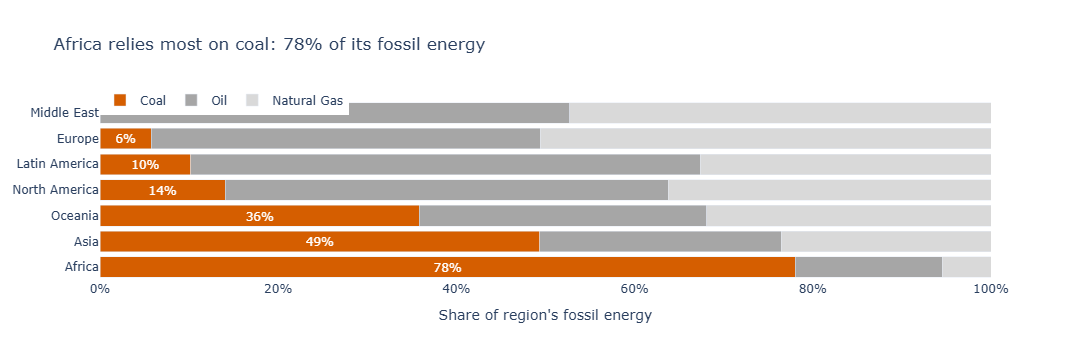

In [10]:
# Task 3

reg = df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh'].sum()
reg['Share'] = reg['TWh'] / reg.groupby('Region')['TWh'].transform('sum') * 100


coal_share = (
    reg.loc[reg['Source'] == 'Coal'].set_index('Region')['Share']
       .reindex(reg['Region'].unique(), fill_value=0)
       .sort_values(ascending=False)
)
region_order = coal_share.index.tolist()
top_coal_region, top_coal_share = region_order[0], coal_share.iloc[0]

fig3 = px.bar(
    reg,
    x='Share', y='Region',
    color='Source',
    orientation='h',
    category_orders={'Source': ['Coal', 'Oil', 'Natural Gas'],   
                     'Region': region_order},
    color_discrete_map={'Coal': fossil_colors['Coal'],           
                        'Oil': '#A6A6A6', 'Natural Gas': '#D9D9D9'},
    title=f"{top_coal_region} relies most on coal: {top_coal_share:.0f}% of its fossil energy"
)


fig3.update_traces(texttemplate='%{x:.0f}%', textposition='inside',
                   insidetextanchor='middle', textfont_color='white',
                   selector=dict(name='Coal'))
fig3.update_traces(hovertemplate='%{y}<br>%{fullData.name}: %{x:.1f}%<extra></extra>')

fig3.update_yaxes(autorange='reversed', title=None)              # highest coal share on top
fig3.update_xaxes(range=[0, 100], ticksuffix='%', title='Share of region\'s fossil energy')
fig3.update_layout(barmode='stack', plot_bgcolor='white', legend_title_text='',
                   legend=dict(orientation='h', y=1.08, x=0))
fig3.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*YOUR ANSWER HERE* 


The treemap shows how much fossil energy each region and country actually uses, like how big China’s coal is compared to a whole region, which the stacked bar can’t since it squishes every region to 100%. The stacked bar shows which region relies most on coal as a share of its fossil mix, which is hard to tell in the treemap because every region’s box is a different size.